# 04. Importancia de variables visuales en ResNet50

Proyecto: diferenciación de defectos superficiales PICADURA y RUSSET en palta Hass.

Sprint 7 · 27–28 de octubre de 2026 · rama GitHub: `sprint-07-importancia-variables`.

Modelo congelado: `FT_D1_PHOTO_s42_01`. Conjunto usado para los análisis: `validation` (127 TIFF elegibles). Cada TIFF completo corresponde a una palta y contiene tres bandas horizontales de cámaras. Ninguna banda se considera una muestra nueva.

Objetivo: caracterizar la sensibilidad de las predicciones a la información de cada cámara y a pequeñas variaciones fotométricas. Se incluye una sección opcional de mapas Grad-CAM.

Este notebook no entrena modelos, no altera TIFF, no cambia umbrales ni pesos, y no infiere sobre TEST. Los resultados del sprint se guardan en una carpeta nueva.

## 1. Diseño del análisis

La importancia de variables en imágenes no se calcula directamente a partir de columnas de una tabla. Se estudia la respuesta del clasificador ante cambios controlados en la información de entrada.

| Evaluación | Intervención | Medida principal |
|:--|:--|:--|
| Referencia | Imagen RGB completa, sin cambios | Macro-F1 de validation |
| Importancia por cámara | Ocultar cada una de las tres franjas, por separado | Diferencia de Macro-F1 respecto a la imagen completa |
| Sensibilidad alternativa | Desenfocar una franja en lugar de ocultarla | Diferencia de Macro-F1 respecto a la referencia |
| Sensibilidad fotométrica | Brillo o contraste multiplicado por 0.95 y 1.05 | Cambios de Macro-F1 y probabilidad de RUSSET |
| Grad-CAM | Mapa de gradientes de la última etapa convolucional | Localización cualitativa de las activaciones |

Una disminución de desempeño por ocultación es evidencia de dependencia del modelo respecto a esa información en estas imágenes, no una estimación causal definitiva de importancia. Las imágenes alteradas pueden estar fuera de la distribución del entrenamiento. El análisis queda restringido a validation.

## 2. Configuración, rutas y protocolo congelado

Abrir el notebook desde `PROYECTO_TI_2` en VS Code con el kernel `palta_gpu (CUDA)`. Se reutilizan las funciones de `utilidades_imagenes.py`. No se ejecuta ninguna acción sobre TEST.

In [12]:
from pathlib import Path
import sys
import gc
import hashlib
import json
from datetime import datetime, timezone

import numpy as np
import pandas as pd
from PIL import Image, ImageEnhance, ImageFilter
from IPython.display import display

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "README.md").is_file()
             and (p / "utilidades_imagenes.py").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra el notebook dentro de PROYECTO_TI_2 en WSL.")
RAIZ = RAIZ.resolve()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from utilidades_imagenes import (
    encontrar_raiz, resolver_dataset, listar_imagenes,
    cargar_rgb, ajustar_tamano, crear_dataset_tf,
)

RAIZ = encontrar_raiz()
DATASET = resolver_dataset(RAIZ, "../DATASET_PALTA")
CLASES = ["PICADURA", "RUSSET"]
SEMILLA = 42
TAMANO = (256, 512)
RUN = "FT_D1_PHOTO_s42_01"
CARPETA_MODELO = RAIZ / "7. resultados" / "entrenamiento" / RUN
CHECKPOINT = CARPETA_MODELO / "mejor_finetune.weights.h5"
SALIDA = RAIZ / "7. resultados" / "importancia_variables" / RUN
SHA_CHECKPOINT_ESPERADO = "d273174144bc2b3a9a2835665a38edf028623bd9ef5eabe6c70a068a9032717e"
RELLENO = (124, 117, 104)

# Las transformaciones operan solo sobre validation.
ANALIZAR_DESENFOQUE = True
EJECUTAR_GRADCAM = True
N_BOOTSTRAP = 500

print("Proyecto:", RAIZ)
print("Modelo:", RUN)
print("Dataset local:", DATASET.is_dir())
print("Partición autorizada: validation")
print("Checkpoint disponible:", CHECKPOINT.is_file())
print("TEST no se utiliza en este notebook.")

Proyecto: /mnt/c/Users/TCI_AUTO/Documents/Maestría UNI/4_2. Proyecto de Invetigación  2/PROYECTO_TI_2
Modelo: FT_D1_PHOTO_s42_01
Dataset local: True
Partición autorizada: validation
Checkpoint disponible: True
TEST no se utiliza en este notebook.


## 3. Identidad del modelo y auditoría de validation

Se contrastan la configuración seleccionada, las exclusiones históricas y los archivos de validation con el inventario del EDA. A continuación se verifica el SHA-256 de cada TIFF elegible de validation frente al registro almacenado. No se calculan huellas de train ni TEST en este sprint.

In [2]:
def leer_json(ruta):
    return json.loads(Path(ruta).read_text(encoding="utf-8-sig"))


def sha256_archivo(ruta):
    h = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            h.update(bloque)
    return h.hexdigest()

requeridos = [
    CARPETA_MODELO / "configuracion.json",
    CARPETA_MODELO / "metricas_validation.json",
    CARPETA_MODELO / "predicciones_validation.csv",
    CARPETA_MODELO / "estado.json",
    RAIZ / "7. resultados" / "eda" / "eda_inventario.csv",
    CHECKPOINT,
]
no_encontrados = [str(p) for p in requeridos if not p.is_file()]
if no_encontrados:
    raise FileNotFoundError("Archivos requeridos:\n" + "\n".join(no_encontrados))

config = leer_json(CARPETA_MODELO / "configuracion.json")
met_val_historicas = leer_json(CARPETA_MODELO / "metricas_validation.json")
estado_modelo = leer_json(CARPETA_MODELO / "estado.json")
if (config.get("condicion") != "FT_D1_PHOTO"
        or config.get("nombre_ejecucion") != RUN
        or list(config.get("clases", [])) != CLASES
        or tuple(config.get("tamano_entrada", [])) != TAMANO):
    raise RuntimeError("La configuración del modelo no corresponde al experimento fijado.")
if estado_modelo.get("estado") != "entrenamiento_completo":
    raise RuntimeError("El entrenamiento guardado no figura como completo.")
if (met_val_historicas.get("particion") != "validation"
        or met_val_historicas.get("firma_protocolo") != config.get("firma_protocolo")):
    raise RuntimeError("La firma de las métricas históricas no coincide.")

exclusiones = set(config.get("exclusiones", []))
if len(exclusiones) != 4:
    raise RuntimeError("El número de exclusiones históricas ha cambiado.")

tabla_val = listar_imagenes(DATASET, "validation", clases=CLASES)
tabla_val = tabla_val.loc[~tabla_val["archivo"].isin(exclusiones)].reset_index(drop=True)
if len(tabla_val) != 127 or tabla_val["archivo"].duplicated().any():
    raise RuntimeError("Validation ya no contiene las 127 imágenes elegibles esperadas.")
if tabla_val["clase"].value_counts().reindex(CLASES, fill_value=0).tolist() != [106, 21]:
    raise RuntimeError("Cambió la distribución de clases de validation.")

inventario = pd.read_csv(RAIZ / "7. resultados" / "eda" / "eda_inventario.csv",
                        encoding="utf-8-sig", keep_default_na=False)
if len(inventario) != 829 or inventario["archivo"].duplicated().any():
    raise RuntimeError("El inventario EDA no corresponde a los 829 registros originales.")
referencias = inventario.set_index("archivo")
no_indexados = set(tabla_val["archivo"]) - set(referencias.index)
if no_indexados:
    raise RuntimeError("Hay TIFF de validation ausentes del inventario EDA.")

print("Verificando SHA-256 local en 127 TIFF de validation ...")
for archivo in tabla_val["archivo"]:
    original = referencias.loc[archivo]
    if (original["particion"] != "validation"
            or original["clase"] != archivo.split("/")[1]
            or sha256_archivo(DATASET / archivo) != original["sha256"]):
        raise RuntimeError("La auditoría local no coincide para: " + archivo)
print("Archivos validation verificados:", len(tabla_val))
display(tabla_val["clase"].value_counts().reindex(CLASES).rename("cantidad").to_frame())
print("Sin acceso a imágenes de TEST para este análisis.")

Verificando SHA-256 local en 127 TIFF de validation ...
Archivos validation verificados: 127


,cantidad
clase,
PICADURA,106
RUSSET,21


Sin acceso a imágenes de TEST para este análisis.


## 4. Reconstrucción de ResNet50 y carga del checkpoint

La red tiene un preprocesamiento ResNet50 interno, global average pooling, Dropout 0.35 y capa Dense softmax de dos clases. Se carga el checkpoint final, se congela y se comprueba su huella. No se descarga ni usa ImageNet durante esta carga (`weights=None`); todos los pesos necesarios se recuperan del archivo local.

In [3]:
def construir_modelo(numero_clases, tamano=TAMANO,
                      volteo_horizontal=False, semilla=SEMILLA, pesos=None):
    import tensorflow as tf
    from tensorflow.keras.applications.resnet50 import preprocess_input

    tf.keras.utils.set_random_seed(semilla)
    entrada = tf.keras.Input(shape=(*tamano, 3), dtype="float32", name="imagen_rgb")
    x = entrada
    if volteo_horizontal:
        x = tf.keras.layers.RandomFlip("horizontal", seed=semilla, name="aumento_train")(x)
    x = tf.keras.layers.Lambda(preprocess_input, name="preprocesamiento_resnet50")(x)
    base = tf.keras.applications.ResNet50(
        input_shape=(*tamano, 3), include_top=False, weights=pesos, pooling="avg")
    base.trainable = False
    x = base(x, training=False)
    x = tf.keras.layers.Dropout(0.35, seed=semilla)(x)
    salida = tf.keras.layers.Dense(
        numero_clases, activation="softmax", name="clase",
        kernel_initializer=tf.keras.initializers.GlorotUniform(seed=semilla))(x)
    modelo = tf.keras.Model(entrada, salida, name="resnet50_palta")
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo

In [4]:
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, precision_score, confusion_matrix,
)
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

# No se modifica ningún checkpoint. La verificación SHA-256 es obligatoria.
SHA_CHECKPOINT = sha256_archivo(CHECKPOINT)
if SHA_CHECKPOINT != SHA_CHECKPOINT_ESPERADO:
    raise RuntimeError("El checkpoint local no coincide con el SHA-256 de la evaluación final.")

tf.keras.backend.clear_session()
modelo = construir_modelo(len(CLASES), tamano=TAMANO, semilla=SEMILLA, pesos=None)
base_resnet = next(capa for capa in modelo.layers if isinstance(capa, tf.keras.Model))
base_resnet.trainable = True
for capa in base_resnet.layers:
    capa.trainable = (capa.name.startswith("conv5_") and
                      not isinstance(capa, tf.keras.layers.BatchNormalization))
modelo.load_weights(str(CHECKPOINT))
modelo.trainable = False

print("Checkpoint SHA-256:", SHA_CHECKPOINT)
print("Capas entrenables de evaluación:", sum(int(x.trainable) for x in modelo.layers))
print("Entrenamiento deshabilitado.")

I0000 00:00:1793344209.980603 1042119 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793344210.445308 1042119 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793344212.763412 1042119 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1793344218.211943 1042119 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5561 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070 Ti Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Checkpoint SHA-256: d273174144bc2b3a9a2835665a38edf028623bd9ef5eabe6c70a068a9032717e
Capas entrenables de evaluación: 0
Entrenamiento deshabilitado.


/home/tci_auto/.venvs/palta_gpu/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(store)


## 5. Línea base reproducida en validation

La entrada se crea con `crear_dataset_tf`, igual que en la evaluación final. Comparamos las 127 probabilidades con el CSV histórico del entrenamiento. Se registran explícitamente las discrepancias numéricas y no se modifican las etiquetas originales.

Durante la evaluación previa hubo una diferencia en una imagen cercana a 0.5. La tolerancia usada aquí es diagnóstica, no implica reproducción exacta ni autoriza cambios de modelo.

In [5]:
def evaluar(probabilidades, etiquetas):
    prob = np.asarray(probabilidades, dtype=np.float64)
    if (prob.shape != (len(etiquetas), 2) or not np.isfinite(prob).all()
            or not np.allclose(prob.sum(axis=1), 1.0, atol=1e-4)):
        raise RuntimeError("Probabilidades inválidas en validation.")
    verdad = np.asarray(etiquetas, dtype=np.int32)
    pred = np.argmax(prob, axis=1)
    return {
        "n": int(len(verdad)),
        "accuracy": float(accuracy_score(verdad, pred)),
        "macro_f1": float(f1_score(verdad, pred, labels=[0, 1],
                                    average="macro", zero_division=0)),
        "recall_russet": float(recall_score(verdad, pred, pos_label=1,
                                            zero_division=0)),
        "precision_russet": float(precision_score(verdad, pred, pos_label=1,
                                                  zero_division=0)),
    }

verdad = tabla_val["etiqueta"].to_numpy(dtype=np.int32)
val_guardada = pd.read_csv(CARPETA_MODELO / "predicciones_validation.csv")
if len(val_guardada) != 127 or val_guardada["archivo"].duplicated().any():
    raise RuntimeError("El CSV histórico de validation cambió.")
val_guardada = val_guardada.set_index("archivo").loc[tabla_val["archivo"]].reset_index()
if not np.array_equal(tabla_val["clase"], val_guardada["clase"]):
    raise RuntimeError("Las etiquetas históricas no corresponden al inventario.")

flujo = crear_dataset_tf(tabla_val, DATASET, tamano=TAMANO,
                        tamano_lote=1, entrenamiento=False, semilla=SEMILLA)
prob_base = np.asarray(modelo.predict(flujo, verbose=0), dtype=np.float32)
metricas_base = evaluar(prob_base, verdad)
pred_base = np.argmax(prob_base, axis=1)
pred_historica = val_guardada["prediccion"].map({c: i for i, c in enumerate(CLASES)}).to_numpy()
if np.isnan(pred_historica.astype(float)).any():
    raise RuntimeError("Clase histórica desconocida en validation.")
prob_hist = val_guardada[[f"probabilidad_{c}" for c in CLASES]].to_numpy(dtype=np.float64)
desacuerdo = np.flatnonzero(pred_base != pred_historica)
diferencia_max = float(np.max(np.abs(prob_base - prob_hist)))
cerca_umbral = all(
    abs(float(prob_base[i, 1]) - 0.5) <= 0.01
    and abs(float(prob_hist[i, 1]) - 0.5) <= 0.01
    for i in desacuerdo
)
compatibilidad = bool(diferencia_max <= 0.02 and len(desacuerdo) <= 1 and cerca_umbral)
if not compatibilidad:
    raise RuntimeError("El checkpoint excede la tolerancia diagnóstica de validation.")

print("Validation:", len(tabla_val), "imágenes")
print("Accuracy recalculado:", round(metricas_base["accuracy"], 4))
print("Macro-F1 recalculado:", round(metricas_base["macro_f1"], 4))
print("Accuracy histórico:", round(float(met_val_historicas["accuracy"]), 4))
print("Macro-F1 histórico:", round(float(met_val_historicas["macro_f1"]), 4))
print("Etiquetas distintas respecto al registro:", len(desacuerdo))
print("Diferencia máxima de probabilidad:", round(diferencia_max, 6))
print("Reproducción exacta:", bool(len(desacuerdo) == 0 and diferencia_max < 1e-7))
print("Compatibilidad diagnóstica:", compatibilidad)

SALIDA.mkdir(parents=True, exist_ok=True)
predicciones_base = tabla_val[["archivo", "particion", "clase", "etiqueta"]].copy()
predicciones_base["prediccion"] = [CLASES[i] for i in pred_base]
for j, clase in enumerate(CLASES):
    predicciones_base[f"probabilidad_{clase}"] = prob_base[:, j]
predicciones_base.to_csv(SALIDA / "predicciones_validation_recalculadas.csv", index=False)
print("Carpeta independiente de resultados:", SALIDA.relative_to(RAIZ))

I0000 00:00:1793344596.911754 1043091 service.cc:153] XLA service 0x734ae8065840 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793344596.911810 1043091 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3070 Ti Laptop GPU, Compute Capability 8.6 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793344597.024559 1043091 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793344597.663577 1043091 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793344602.137550 1043091 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Validation: 127 imágenes
Accuracy recalculado: 0.8661
Macro-F1 recalculado: 0.7781
Accuracy histórico: 0.874
Macro-F1 histórico: 0.7876
Etiquetas distintas respecto al registro: 1
Diferencia máxima de probabilidad: 0.004967
Reproducción exacta: False
Compatibilidad diagnóstica: True
Carpeta independiente de resultados: 7. resultados/importancia_variables/FT_D1_PHOTO_s42_01


## 6. Importancia de las tres cámaras

Se interviene una sola franja horizontal del TIFF original por vez. El resto de las vistas permanece intacto. Las franjas se definen como los tres segmentos del alto de la imagen original, no del tensor redimensionado, para respetar la geometría de la captura.

La primera intervención sustituye una franja por el color de relleno neutro del preprocesamiento. La segunda, de sensibilidad, desenfoca esa franja con un filtro gaussiano. Cada condición se evalúa sobre las mismas 127 paltas y se compara de forma emparejada con la imagen completa.

Definimos importancia operativa por ocultación como `Macro-F1 (completa) − Macro-F1 (franja alterada)`. Un resultado positivo refleja pérdida de desempeño al alterar esa cámara; uno negativo refleja mejoría accidental y no debe interpretarse como importancia negativa causal.

In [7]:
def transformar_imagen(imagen, camara=None, metodo=None,
                       fotometria=None, factor=1.0):
    # La copia se construye en RAM. Nunca se escribe sobre el TIFF.
    if camara is not None:
        if camara not in (1, 2, 3) or metodo not in ("ocultar", "desenfocar"):
            raise ValueError("Cámara o transformación no reconocida.")
        matriz = np.asarray(imagen.convert("RGB"), dtype=np.uint8).copy()
        h = matriz.shape[0]
        cortes = np.linspace(0, h, 4, dtype=int)
        y0, y1 = int(cortes[camara - 1]), int(cortes[camara])
        if metodo == "ocultar":
            matriz[y0:y1, :, :] = np.asarray(RELLENO, dtype=np.uint8)
        else:
            desenfocada = np.asarray(
                imagen.filter(ImageFilter.GaussianBlur(radius=24)), dtype=np.uint8)
            matriz[y0:y1, :, :] = desenfocada[y0:y1, :, :]
        imagen = Image.fromarray(matriz, mode="RGB")
    if fotometria == "brillo":
        imagen = ImageEnhance.Brightness(imagen).enhance(float(factor))
    elif fotometria == "contraste":
        imagen = ImageEnhance.Contrast(imagen).enhance(float(factor))
    elif fotometria is not None:
        raise ValueError("Transformación fotométrica no reconocida.")
    return imagen


def predecir_condicion(camara=None, metodo=None, fotometria=None, factor=1.0):
    entradas = []
    for ruta_relativa in tabla_val["archivo"]:
        img = cargar_rgb(DATASET / ruta_relativa)
        modificada = transformar_imagen(img, camara=camara, metodo=metodo,
                                       fotometria=fotometria, factor=factor)
        matriz, _ = ajustar_tamano(modificada, tamano=TAMANO,
                                  color_relleno=RELLENO)
        entradas.append(matriz.astype(np.float32))
    lote = np.stack(entradas, axis=0)
    prob = np.asarray(modelo.predict(lote, batch_size=1, verbose=0), dtype=np.float32)
    del lote, entradas
    gc.collect()
    evaluar(prob, verdad)
    return prob


def descripcion_condicion(nombre, prob):
    metricas = evaluar(prob, verdad)
    metricas.update({
        "condicion": nombre,
        "delta_macro_f1": float(metricas_base["macro_f1"] - metricas["macro_f1"]),
        "delta_accuracy": float(metricas_base["accuracy"] - metricas["accuracy"]),
        "cambios_etiqueta": int(np.sum(np.argmax(prob, axis=1) != pred_base)),
        "cambio_promedio_abs_p_russet": float(np.mean(np.abs(prob[:, 1] - prob_base[:, 1]))),
    })
    return metricas


def intervalo_bootstrap_delta(prob_modificada, n=N_BOOTSTRAP, semilla=SEMILLA):
    # Remuestreo emparejado, estratificado por clase, a nivel de TIFF/fruto.
    generador = np.random.default_rng(semilla)
    idx0 = np.flatnonzero(verdad == 0)
    idx1 = np.flatnonzero(verdad == 1)
    pred_mod = np.argmax(prob_modificada, axis=1)
    valores = np.empty(n, dtype=np.float64)
    for it in range(n):
        indices = np.concatenate([
            generador.choice(idx0, size=len(idx0), replace=True),
            generador.choice(idx1, size=len(idx1), replace=True),
        ])
        f_base = f1_score(verdad[indices], pred_base[indices],
                          labels=[0, 1], average="macro", zero_division=0)
        f_mod = f1_score(verdad[indices], pred_mod[indices],
                         labels=[0, 1], average="macro", zero_division=0)
        valores[it] = f_base - f_mod
    return [float(x) for x in np.percentile(valores, [2.5, 97.5])]

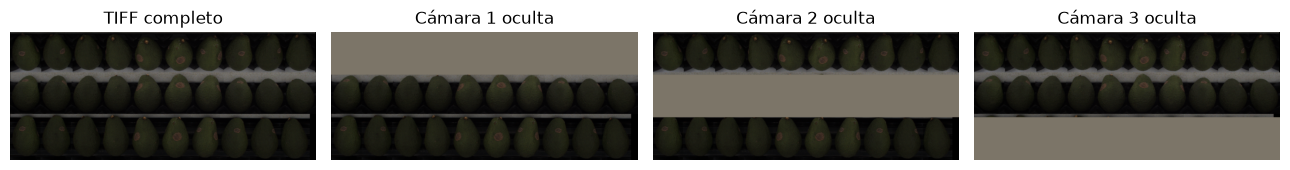

TIFF original conservado; muestra visual de validation únicamente.


In [8]:
# Comprobación visual de la ubicación de las tres franjas.
img_ejemplo = cargar_rgb(DATASET / tabla_val.loc[0, "archivo"])
fig, ejes = plt.subplots(1, 4, figsize=(13, 3.6))
for indice, (camara, titulo) in enumerate([
    (None, "TIFF completo"), (1, "Cámara 1 oculta"),
    (2, "Cámara 2 oculta"), (3, "Cámara 3 oculta"),
]):
    copia = (img_ejemplo if camara is None
             else transformar_imagen(img_ejemplo, camara=camara, metodo="ocultar"))
    ejes[indice].imshow(copia)
    ejes[indice].set_title(titulo)
    ejes[indice].axis("off")
fig.tight_layout()
fig.savefig(SALIDA / "ejemplo_ocultacion_camaras_validation.png", dpi=160)
plt.show()
plt.close(fig)
print("TIFF original conservado; muestra visual de validation únicamente.")

Evaluando: camara_1_ocultar
Evaluando: camara_2_ocultar
Evaluando: camara_3_ocultar
Evaluando: camara_1_desenfocar
Evaluando: camara_2_desenfocar
Evaluando: camara_3_desenfocar


,n,accuracy,macro_f1,recall_russet,precision_russet,condicion,delta_macro_f1,delta_accuracy,cambios_etiqueta,cambio_promedio_abs_p_russet,ic95_delta_macro_f1_inf,ic95_delta_macro_f1_sup
0,127,0.8898,0.7354,0.3810,0.8889,camara_1_ocultar,0.0427,-0.0236,19,0.1372,-0.0850,0.1913
1,127,0.8583,0.7883,0.8571,0.5455,camara_2_ocultar,-0.0102,0.0079,11,0.0881,-0.0965,0.0561
2,127,0.6457,0.6066,1.0000,0.3182,camara_3_ocultar,0.1714,0.2205,40,0.2573,0.0678,0.2759
3,127,0.6929,0.6120,0.7143,0.3125,camara_1_desenfocar,0.1661,0.1732,26,0.1887,0.0914,0.2405
4,127,0.7795,0.6945,0.7619,0.4103,camara_2_desenfocar,0.0836,0.0866,17,0.1280,-0.0046,0.1647
5,127,0.5906,0.5609,1.0000,0.2877,camara_3_desenfocar,0.2172,0.2756,47,0.3176,0.1160,0.3188


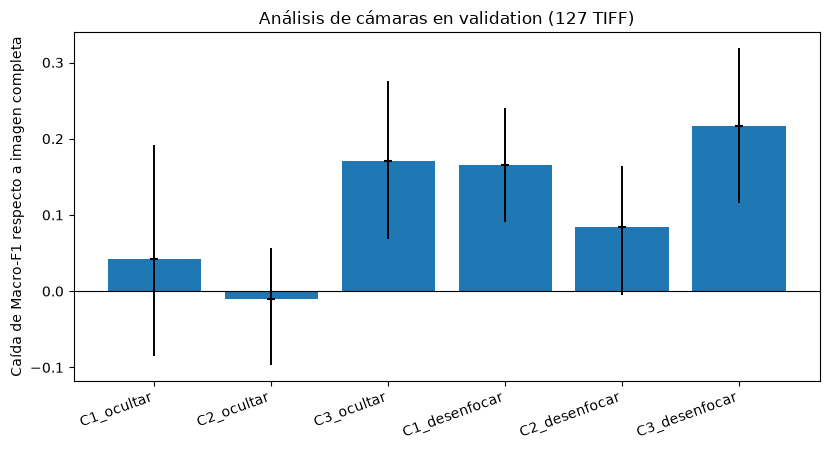

Resultados guardados sin modificar predicciones históricas ni TEST.


In [9]:
resultados_camaras = []
probabilidades_camaras = {}

for metodo in (["ocultar", "desenfocar"] if ANALIZAR_DESENFOQUE else ["ocultar"]):
    for camara in (1, 2, 3):
        nombre = f"camara_{camara}_{metodo}"
        print("Evaluando:", nombre)
        prob = predecir_condicion(camara=camara, metodo=metodo)
        probabilidades_camaras[nombre] = prob
        fila = descripcion_condicion(nombre, prob)
        lim_inf, lim_sup = intervalo_bootstrap_delta(prob)
        fila["ic95_delta_macro_f1_inf"] = lim_inf
        fila["ic95_delta_macro_f1_sup"] = lim_sup
        resultados_camaras.append(fila)

tabla_camaras = pd.DataFrame(resultados_camaras)
tabla_camaras.to_csv(SALIDA / "importancia_camaras_validation.csv", index=False)
display(tabla_camaras.round(4))

fig, ax = plt.subplots(figsize=(8.4, 4.6))
condiciones = tabla_camaras["condicion"].str.replace("camara_", "C", regex=False)
pos = np.arange(len(tabla_camaras))
ax.bar(pos, tabla_camaras["delta_macro_f1"])
ax.vlines(pos, tabla_camaras["ic95_delta_macro_f1_inf"],
          tabla_camaras["ic95_delta_macro_f1_sup"], color="black", linewidth=1.4)
ax.scatter(pos, tabla_camaras["delta_macro_f1"], marker="_", color="black", zorder=3)
ax.set_xticks(pos, condiciones, rotation=20, ha="right")
ax.set_ylabel("Caída de Macro-F1 respecto a imagen completa")
ax.set_title("Análisis de cámaras en validation (127 TIFF)")
ax.axhline(0, color="black", linewidth=0.8)
fig.tight_layout()
fig.savefig(SALIDA / "importancia_camaras_validation.png", dpi=170)
plt.show()
plt.close(fig)
print("Resultados guardados sin modificar predicciones históricas ni TEST.")

## 7. Sensibilidad a brillo y contraste

Se estudian factores suaves, iguales a los empleados como rango fotométrico durante el entrenamiento final: 0.95 y 1.05. Aquí se aplican de forma fija y determinista para medir sensibilidad en validation; no se utilizan como aumentos para entrenar.

Cada intervención se realiza sobre el TIFF completo antes de ejecutar el mismo redimensionamiento y la misma normalización interna de ResNet50.

Evaluando: brillo_0.95
Evaluando: brillo_1.05
Evaluando: contraste_0.95
Evaluando: contraste_1.05


,n,accuracy,macro_f1,recall_russet,precision_russet,condicion,delta_macro_f1,delta_accuracy,cambios_etiqueta,cambio_promedio_abs_p_russet
0,127,0.8819,0.7900,0.6667,0.6364,brillo_0.95,-0.0120,-0.0157,4,0.0117
1,127,0.8661,0.7781,0.7143,0.5769,brillo_1.05,0.0000,0.0000,0,0.0109
2,127,0.8819,0.7974,0.7143,0.6250,contraste_0.95,-0.0194,-0.0157,2,0.0097
3,127,0.8661,0.7781,0.7143,0.5769,contraste_1.05,0.0000,0.0000,0,0.0126


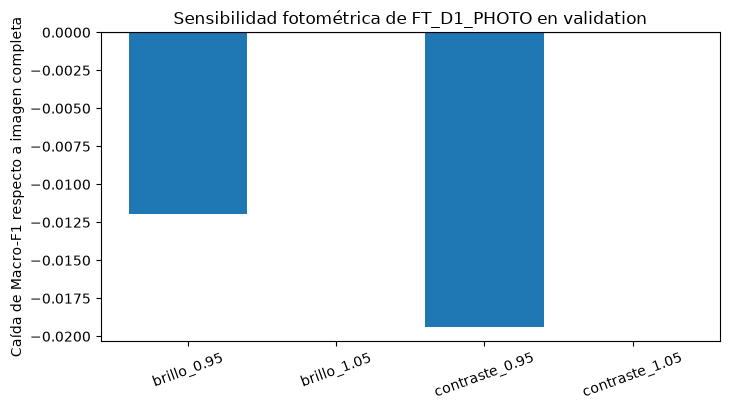

In [10]:
resultados_fotometricos = []
probabilidades_fotometricas = {}
for variable in ("brillo", "contraste"):
    for factor in (0.95, 1.05):
        nombre = f"{variable}_{factor:.2f}"
        print("Evaluando:", nombre)
        prob = predecir_condicion(fotometria=variable, factor=factor)
        probabilidades_fotometricas[nombre] = prob
        resultados_fotometricos.append(descripcion_condicion(nombre, prob))

tabla_fotometrica = pd.DataFrame(resultados_fotometricos)
tabla_fotometrica.to_csv(SALIDA / "sensibilidad_fotometrica_validation.csv", index=False)
display(tabla_fotometrica.round(4))

fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.bar(tabla_fotometrica["condicion"], tabla_fotometrica["delta_macro_f1"])
ax.set_ylabel("Caída de Macro-F1 respecto a imagen completa")
ax.set_title("Sensibilidad fotométrica de FT_D1_PHOTO en validation")
ax.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=20)
fig.tight_layout()
fig.savefig(SALIDA / "sensibilidad_fotometrica_validation.png", dpi=170)
plt.show()
plt.close(fig)

## 8. Mapas Grad-CAM (visualización opcional)

Grad-CAM utiliza los gradientes de la puntuación de clase respecto a la última representación convolucional de ResNet50. Se seleccionan ejemplos de validation, sin consultar ni inferir sobre TEST. Una activación intensa no es, por sí sola, una prueba de que el modelo localiza el defecto de forma correcta.

Para generar los mapas, activar `EJECUTAR_GRADCAM = True` en la celda de configuración y ejecutar la celda siguiente. Esta parte requiere memoria adicional en GPU y se mantiene desactivada por defecto.

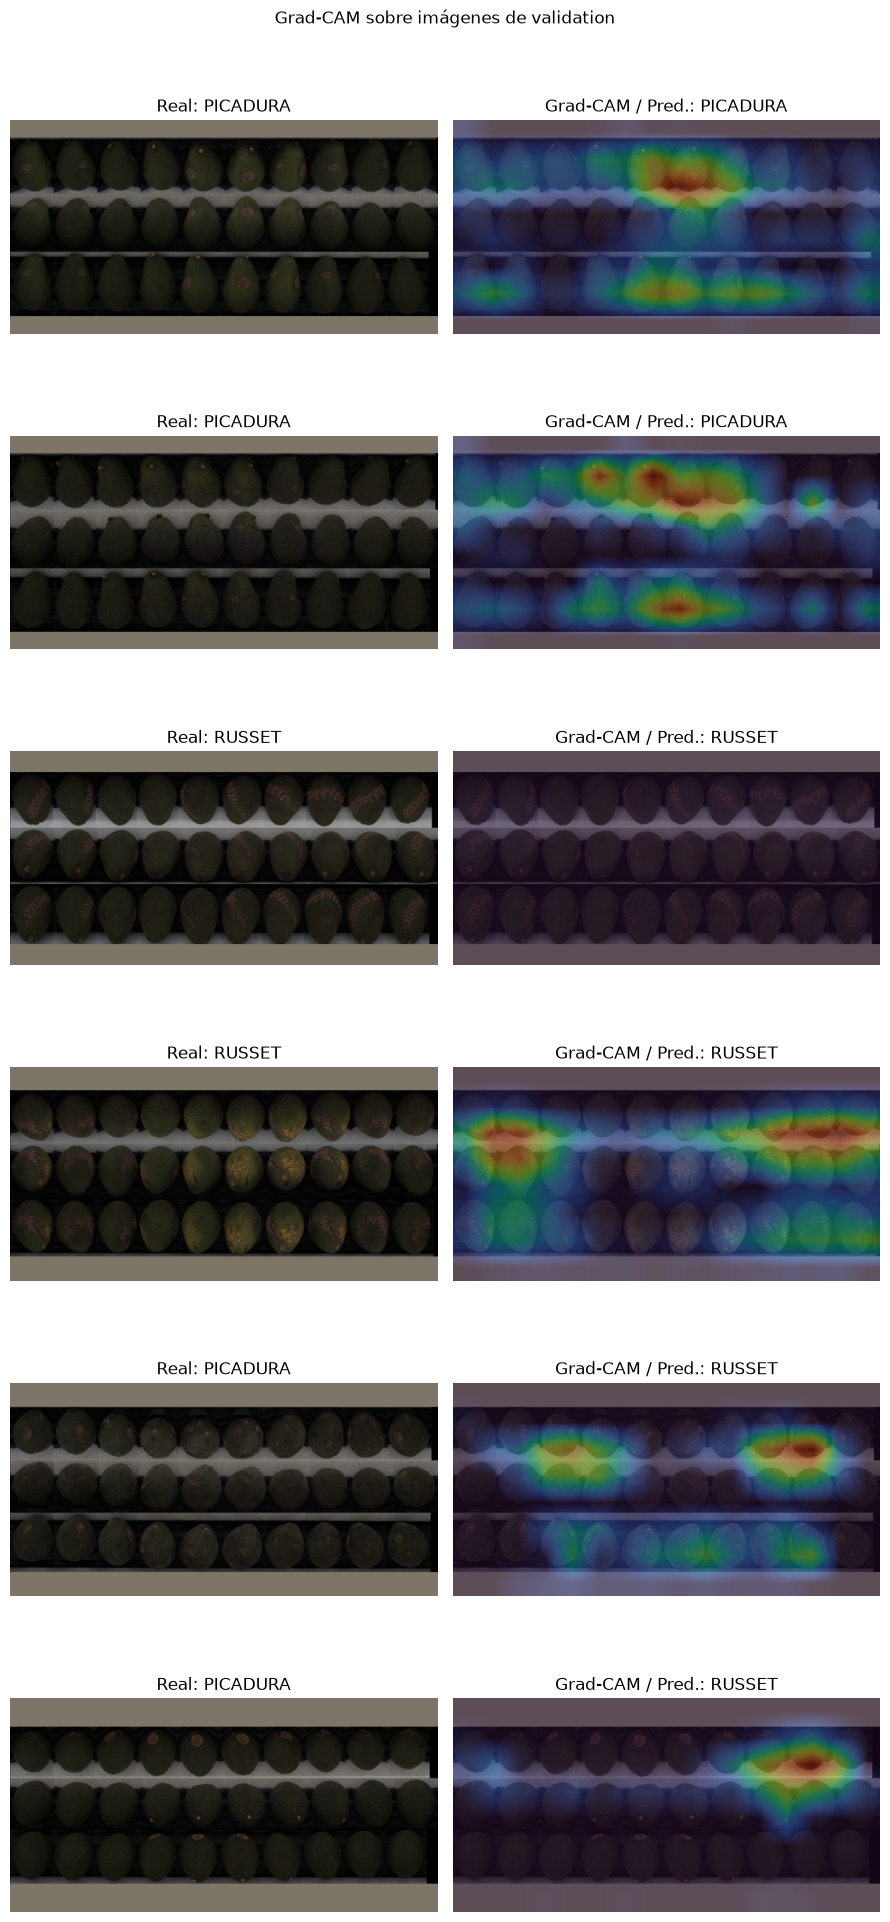

Mapas Grad-CAM guardados: 6


In [13]:
def obtener_mapa_gradcam(imagen_preparada, indice_clase):
    capa_cam = base_resnet.get_layer("conv5_block3_out")
    red_grad = tf.keras.Model(
        inputs=base_resnet.inputs,
        outputs=[capa_cam.output, base_resnet.output],
    )
    entrada = tf.convert_to_tensor(imagen_preparada[None, ...], dtype=tf.float32)
    x = modelo.get_layer("preprocesamiento_resnet50")(entrada)
    capa_dropout = next(c for c in modelo.layers if isinstance(c, tf.keras.layers.Dropout))
    capa_clase = modelo.get_layer("clase")
    with tf.GradientTape() as cinta:
        mapas_conv, vector = red_grad(x, training=False)
        vector = capa_dropout(vector, training=False)
        probabilidades = capa_clase(vector)
        puntuacion = probabilidades[:, indice_clase]
    gradientes = cinta.gradient(puntuacion, mapas_conv)
    if gradientes is None:
        raise RuntimeError("No fue posible calcular gradientes de Grad-CAM.")
    pesos = tf.reduce_mean(gradientes, axis=(1, 2))
    mapa = tf.reduce_sum(mapas_conv[0] * pesos[0][None, None, :], axis=-1)
    mapa = tf.maximum(mapa, 0)
    mapa = mapa / (tf.reduce_max(mapa) + 1e-8)
    return mapa.numpy()

if EJECUTAR_GRADCAM:
    # Dos aciertos por clase y hasta dos errores, siempre de validation.
    elegidos = []
    for clase_id in (0, 1):
        correctos = np.flatnonzero((verdad == clase_id) & (pred_base == clase_id))
        elegidos.extend(correctos[:2].tolist())
    fallos = np.flatnonzero(verdad != pred_base)
    elegidos.extend(fallos[:2].tolist())
    elegidos = list(dict.fromkeys(elegidos))

    fig, ejes = plt.subplots(len(elegidos), 2, figsize=(9, 3.3 * len(elegidos)), squeeze=False)
    for fila, i in enumerate(elegidos):
        imagen = cargar_rgb(DATASET / tabla_val.loc[i, "archivo"])
        rgb, _ = ajustar_tamano(imagen, tamano=TAMANO, color_relleno=RELLENO)
        gradcam = obtener_mapa_gradcam(rgb.astype(np.float32), int(pred_base[i]))
        gradcam_imagen = Image.fromarray(np.uint8(gradcam * 255))
        gradcam_red = gradcam_imagen.resize((TAMANO[1], TAMANO[0]), Image.Resampling.BILINEAR)
        mapa = np.asarray(gradcam_red, dtype=np.float32) / 255.0
        colores = plt.colormaps["turbo"](mapa)[:, :, :3]
        combinado = np.clip(0.60 * (rgb / 255.0) + 0.40 * colores, 0.0, 1.0)
        ejes[fila, 0].imshow(rgb)
        ejes[fila, 0].set_title(f"Real: {CLASES[verdad[i]]}")
        ejes[fila, 1].imshow(combinado)
        ejes[fila, 1].set_title(f"Grad-CAM / Pred.: {CLASES[pred_base[i]]}")
        for ax in ejes[fila]:
            ax.axis("off")
    fig.suptitle("Grad-CAM sobre imágenes de validation", y=1.0)
    fig.tight_layout()
    fig.savefig(SALIDA / "gradcam_ejemplos_validation.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Mapas Grad-CAM guardados:", len(elegidos))
else:
    print("Grad-CAM opcional: no ejecutado. Actívelo en la configuración cuando disponga de GPU.")

## 9. Resumen comparativo y archivo de trazabilidad

La línea base se recalcula con el checkpoint actual. Los resultados del nuevo sprint se guardan en `7. resultados/importancia_variables/FT_D1_PHOTO_s42_01/`. No se guardan predicciones del conjunto TEST.

Interpretación: comparar la caída de Macro-F1 por cada intervención, el número de cambios de etiqueta y el cambio promedio absoluto de probabilidad RUSSET. Para el análisis por cámara se incluye un intervalo bootstrap pareado estratificado, cuyo significado es exploratorio porque el conjunto validation es limitado y pueden existir dependencias por captura.

In [14]:
tabla_resumen = pd.concat([
    pd.DataFrame([descripcion_condicion("imagen_completa", prob_base)]),
    tabla_camaras,
    tabla_fotometrica,
], ignore_index=True)
tabla_resumen.to_csv(SALIDA / "resumen_importancia_validation.csv", index=False)

registro = {
    "sprint": "07_importancia_variables",
    "modelo": RUN,
    "particion": "validation",
    "n_imagenes": int(len(tabla_val)),
    "n_picadura": int(np.sum(verdad == 0)),
    "n_russet": int(np.sum(verdad == 1)),
    "sha256_checkpoint": SHA_CHECKPOINT,
    "firma_protocolo": config["firma_protocolo"],
    "metodo_camara": "ocultacion_y_desenfoque_de_tercio_horizontal_en_TIFF_original",
    "metodo_fotometrico": "brillo_y_contraste_fijos_0.95_1.05",
    "bootstrap_remuestreo": "emparejado_estratificado_por_clase_en_unidad_TIFF",
    "bootstrap_repeticiones": N_BOOTSTRAP,
    "reproduccion_exacta_validation": bool(len(desacuerdo) == 0 and diferencia_max < 1e-7),
    "diferencia_max_probabilidad_validation_historica": diferencia_max,
    "etiquetas_distintas_validation_historica": int(len(desacuerdo)),
    "test_inferido": False,
    "modelo_reentrenado": False,
    "gradcam_ejecutado": bool(EJECUTAR_GRADCAM),
    "fecha_utc": datetime.now(timezone.utc).isoformat(),
}
(SALIDA / "protocolo_importancia.json").write_text(
    json.dumps(registro, indent=2, ensure_ascii=False), encoding="utf-8")

print("Resumen de las intervenciones:")
display(tabla_resumen[["condicion", "accuracy", "macro_f1", "recall_russet",
                       "delta_macro_f1", "cambios_etiqueta",
                       "cambio_promedio_abs_p_russet"]].round(4))
print("Archivos del sprint guardados en:", SALIDA.relative_to(RAIZ))
print("Entrenamiento nuevo: no. Inferencia en TEST: no.")

Resumen de las intervenciones:


,condicion,accuracy,macro_f1,recall_russet,delta_macro_f1,cambios_etiqueta,cambio_promedio_abs_p_russet
0,imagen_completa,0.8661,0.7781,0.7143,0.0000,0,0.0000
1,camara_1_ocultar,0.8898,0.7354,0.3810,0.0427,19,0.1372
2,camara_2_ocultar,0.8583,0.7883,0.8571,-0.0102,11,0.0881
3,camara_3_ocultar,0.6457,0.6066,1.0000,0.1714,40,0.2573
4,camara_1_desenfocar,0.6929,0.6120,0.7143,0.1661,26,0.1887
5,camara_2_desenfocar,0.7795,0.6945,0.7619,0.0836,17,0.1280
6,camara_3_desenfocar,0.5906,0.5609,1.0000,0.2172,47,0.3176
7,brillo_0.95,0.8819,0.7900,0.6667,-0.0120,4,0.0117
8,brillo_1.05,0.8661,0.7781,0.7143,0.0000,0,0.0109
9,contraste_0.95,0.8819,0.7974,0.7143,-0.0194,2,0.0097


Archivos del sprint guardados en: 7. resultados/importancia_variables/FT_D1_PHOTO_s42_01
Entrenamiento nuevo: no. Inferencia en TEST: no.


In [15]:
ocultaciones = tabla_camaras[tabla_camaras["condicion"].str.endswith("_ocultar")]
mayor = ocultaciones.sort_values("delta_macro_f1", ascending=False).iloc[0]
mayor_foto = tabla_fotometrica.iloc[tabla_fotometrica["delta_macro_f1"].abs().argmax()]

filas_resumen = ["| Condición | Accuracy | Macro-F1 | Δ Macro-F1 | Cambios de etiqueta |",
                 "|:--|--:|--:|--:|--:|"]
for _, fila in tabla_resumen.iterrows():
    filas_resumen.append(
        f"| {fila['condicion']} | {fila['accuracy']:.4f} | {fila['macro_f1']:.4f} | "
        f"{fila['delta_macro_f1']:+.4f} | {int(fila['cambios_etiqueta'])} |")

texto = [
    "# Sprint 7. Análisis de importancia de variables visuales",
    "",
    f"Modelo: {RUN}.",
    "Partición utilizada: validation, 127 TIFF completos (106 PICADURA y 21 RUSSET).",
    "No se realizó entrenamiento ni se volvió a evaluar TEST.",
    "",
    "## Resultados observados",
    "",
    *filas_resumen,
    "",
    "## Interpretación descriptiva",
    "",
    f"Entre las ocultaciones, {mayor['condicion']} produjo la mayor caída observada "
    f"de Macro-F1 ({mayor['delta_macro_f1']:+.4f}). "
    "Esta relación es de sensibilidad bajo intervención artificial, no causalidad.",
    f"La mayor variación absoluta del Macro-F1 entre los cambios fotométricos "
    f"se observó en {mayor_foto['condicion']} "
    f"(Δ={mayor_foto['delta_macro_f1']:+.4f}).",
    f"La reproducción de validation difirió del registro histórico en "
    f"{len(desacuerdo)} etiquetas y su diferencia máxima de probabilidad fue "
    f"{diferencia_max:.6f}; no se considera una reproducción exacta si hay discordancias.",
    "",
    "## Limitaciones",
    "",
    "El conjunto validation es limitado y presenta desbalance. "
    "La ocultación/desenfoque introduce imágenes modificadas, "
    "que pueden quedar fuera de la distribución original. "
    "Las estimaciones no equivalen a importancia causal ni prueban robustez industrial.",
    "La evaluación TEST permanece cerrada desde el corte anterior.",
    "",
    "## Evidencia generada",
    "",
    "- importancia_camaras_validation.csv",
    "- sensibilidad_fotometrica_validation.csv",
    "- resumen_importancia_validation.csv",
    "- protocolo_importancia.json",
    "- importancia_camaras_validation.png",
    "- sensibilidad_fotometrica_validation.png",
    "- gradcam_ejemplos_validation.png (solo si se activa Grad-CAM)",
]
(SALIDA / "reporte_sensibilidad_validation.md").write_text(
    "\n".join(texto) + "\n", encoding="utf-8")
print("Reporte descriptivo creado:", (SALIDA / "reporte_sensibilidad_validation.md").relative_to(RAIZ))

Reporte descriptivo creado: 7. resultados/importancia_variables/FT_D1_PHOTO_s42_01/reporte_sensibilidad_validation.md


## 10. Análisis crítico para el informe de investigación

Los resultados de este notebook permiten responder qué partes de la información visual afectan más las decisiones del modelo en validation. La importancia operativa se calcula respecto a la línea base reproducida en esta misma ejecución y no respecto a los valores históricos de otro entorno de inferencia.

Pautas para reportar los resultados después de ejecutar las celdas:

1. Indicar qué cámara produjo la mayor caída de Macro-F1 al ocultarla, con su intervalo de remuestreo.
2. Contrastar si ese orden es semejante cuando la franja se desenfoca en vez de ocultarse.
3. Informar si el brillo y el contraste producen cambios de clasificación o únicamente cambios leves en las puntuaciones.
4. Usar Grad-CAM solo como evidencia visual complementaria, no como una métrica causal de importancia.
5. Documentar las diferencias entre el historial de validation y su reproducción actual; no presentar la reproducción como idéntica si difiere una imagen.
6. Conservar los 7 errores finales de TEST y las métricas 0.9444 de accuracy, 0.9019 de Macro-F1 y 0.9000 de recall RUSSET únicamente como antecedente final ya fijado. Estos resultados no deben utilizarse para ajustar el análisis de validation ni para reabrir TEST.

Limitaciones: solo 127 imágenes de validation, desbalance 106/21, posibles semejanzas por captura, sustituciones fuera de distribución, y ausencia de anotaciones espaciales de defectos. Un mapa de activación no constituye detección espacial supervisada.

El cumplimiento de la segunda hipótesis de la matriz de consistencia se evalúa después de ejecutar el análisis. No se anticipa su aceptación ni se inventan resultados.